[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmedelshazly27/mizan-kuwait-energy-toolkit/blob/main/notebooks/04-weather.ipynb)

In [1]:
# On Colab: clone the repository and install it (inputs are committed, no credentials needed).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("mizan-kuwait-energy-toolkit"):
    !git clone --depth 1 https://github.com/ahmedelshazly27/mizan-kuwait-energy-toolkit.git
    %pip install -q -e "mizan-kuwait-energy-toolkit[pv,econ,system]" matplotlib
    os.chdir("mizan-kuwait-energy-toolkit")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from kwtk import viz; viz.style()

# 4. Weather and solar resource

ERA5 reanalysis for every 0.25° cell over Kuwait (45 cells, hourly 2013-2024), stored
in `inputs/weather/grid/`. A plant uses its nearest cell.

In [2]:
from kwtk.inputs import era5
rows = []
for la, lo in era5.CELLS:
    if era5._cell_file(la, lo).exists():
        w = era5.site_weather(la, lo, [2019, 2020, 2021, 2022, 2023])
        rows.append({'lat': la, 'lon': lo, 'ghi_kwh_m2_yr': w.ghi.sum() / 1000 / 5, 'dni_kwh_m2_yr': w.dni.sum() / 1000 / 5,
                     'mean_temp_c': w.temp_air.mean(), 'rain_mm_yr': w.precip_mm.sum() / 5})
g = pd.DataFrame(rows); g.describe().round(1)

,lat,lon,ghi_kwh_m2_yr,dni_kwh_m2_yr,mean_temp_c,rain_mm_yr
count,45.0,45.0,45.0,45.0,45.0,45.0
mean,29.3,47.6,2152.1,2493.6,27.0,121.8
std,0.5,0.6,29.2,13.0,0.6,12.5
min,28.5,46.5,2089.0,2471.6,25.8,102.3
25%,29.0,47.2,2133.4,2482.5,26.6,112.6
50%,29.2,47.8,2159.5,2491.1,27.1,120.2
75%,29.8,48.0,2177.8,2503.0,27.5,130.0
max,30.0,48.5,2187.0,2518.9,28.1,158.5


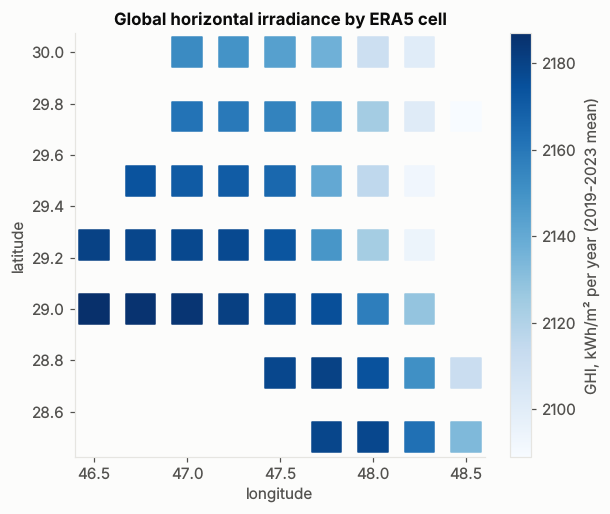

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(g.lon, g.lat, c=g.ghi_kwh_m2_yr, cmap='Blues', s=380, marker='s')
plt.colorbar(sc, label='GHI, kWh/m² per year (2019-2023 mean)')
ax.set_title('Global horizontal irradiance by ERA5 cell'); ax.set_xlabel('longitude'); ax.set_ylabel('latitude'); ax.grid(False)
plt.show()

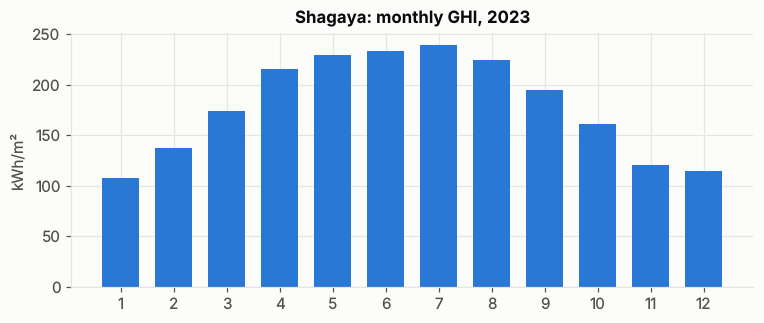

In [4]:
w = era5.site_weather(29.2055, 47.0524, [2023])
m = w.groupby(w.index.month).agg(ghi=('ghi', 'sum'), temp=('temp_air', 'mean'))
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(m.index, m.ghi / 1000, width=0.7); ax.set_title('Shagaya: monthly GHI, 2023'); ax.set_ylabel('kWh/m²'); ax.set_xticks(range(1, 13))
plt.show()